# 🌾 AgriGuard: Deep Learning for Computer Vision (CSE471)
## Capstone Project: Early Detection & Management of Crop Diseases and Pest Infestations
**Course Code:** CSE471 (Deep Learning for Computer Vision) | **Session:** 2026–2027  
**Frameworks:** PyTorch 2.11 + CUDA 12.8, Ultralytics YOLOv8n, OpenCV, ONNX Runtime  
**Target Deployment:** Android Mobile PWA (Offline Service Worker) & Native Android Studio APK  

---

### 📋 Syllabus Mapping & Course Outcomes (CO1 – CO6):
| Unit | Syllabus Module | Project Implementation & Practical Covered |
| :--- | :--- | :--- |
| **Unit I** | Foundations of CV & Deep Learning | Image representation (RGB/HSV), ImageNet normalization, NumPy 2D convolution *(Practicals 1, 2, 3)* |
| **Unit II** | CNNs & Regularization Techniques | Residual skip connections, Mosaic & MixUp augmentation, Cosine Annealing schedule *(Practical 4)* |
| **Unit III** | Transfer Learning & Fine-Tuning | MobileNetV3 / ResNet feature extraction, layer freezing/unfreezing, discriminative LRs *(Practicals 5, 6)* |
| **Unit IV** | Object Detection & Localization | Bounding box $(x_c, y_c, w, h)$, IoU, NMS, CIoU Loss, YOLOv8 GPU training, mAP@50 *(Practicals 7, 8)* |
| **Unit V** | Image Segmentation & Transformers | Lesion segmentation mask formulation, severity percentage, Self-Attention & SE attention *(Practical 9)* |
| **Unit VI** | Generative Models & Interpretability | **Grad-CAM Saliency Heatmaps** *(Practical 10)*, synthetic augmentation, and Multimodal Conversational UI (CLIP/LLM) |

## 0. Hardware & Environment Verification (PyTorch + CUDA)

In [1]:
import os
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import ultralytics
from ultralytics import YOLO

print(f"Python Version: {sys.version.split()[0]}")
print(f"PyTorch Version: {torch.__version__}")
print(f"OpenCV Version: {cv2.__version__}")
print(f"Ultralytics YOLO Version: {ultralytics.__version__}")
print(f"CUDA GPU Acceleration Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Active GPU: {torch.cuda.get_device_name(0)}")
    print(f"Allocated VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")

Python Version: 3.10.18
PyTorch Version: 2.11.0+cu128
OpenCV Version: 5.0.0
Ultralytics YOLO Version: 8.4.212
CUDA GPU Acceleration Available: True
Active GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Allocated VRAM: 8.00 GB


## Unit I: Foundations of Computer Vision and Deep Learning (CO1)
*(Corresponding to Practicals 1, 2, and 3)*
- Image representation: Pixels, channels, and color spaces (RGB vs HSV vs Grayscale).
- Chlorophyll vs Chlorosis separation in HSV space (Hue channel isolating yellowing/browning lesions).
- Resizing, cropping, and tensor normalization with ImageNet constants ($\mu = [0.485, 0.456, 0.406]$, $\sigma = [0.229, 0.224, 0.225]$).
- NumPy implementation of 2D spatial convolution with custom Sobel edge and Gaussian smoothing kernels.

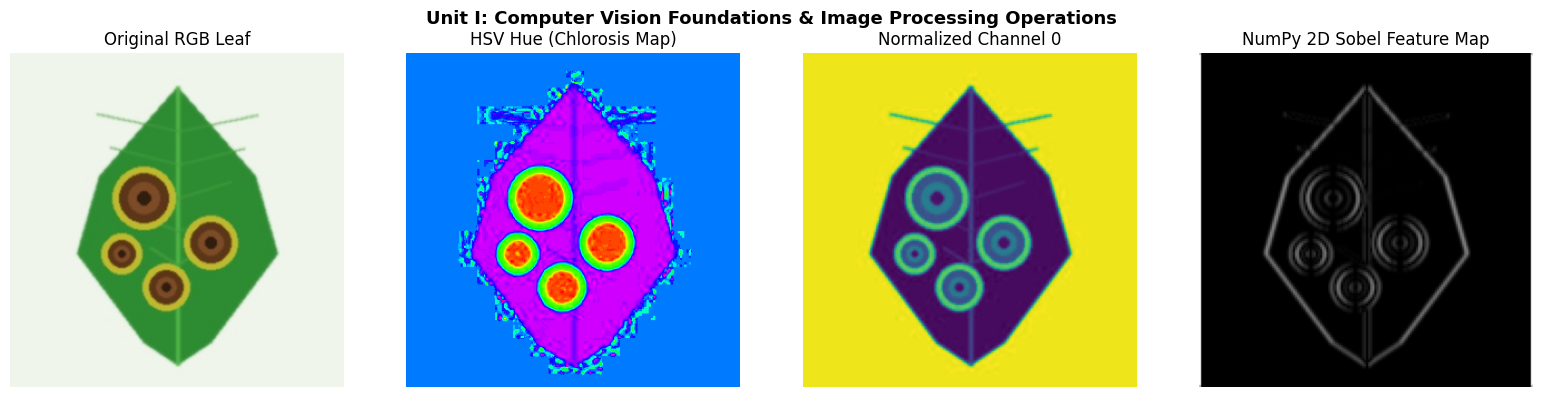

In [2]:
# Practical 1: Load image, color space conversion, and normalization
sample_path = "../../Data/sample_images/tomato_early_blight_sample.jpg"
img_bgr = cv2.imread(sample_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# ImageNet Normalization
img_resized = cv2.resize(img_rgb, (224, 224)).astype(np.float32) / 255.0
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
img_norm = (img_resized - mean) / std

# Practical 2 & 3: 2D Spatial Convolution with NumPy (Sobel Horizontal & Vertical)
def convolve2d(image, kernel):
    kh, kw = kernel.shape
    ih, iw = image.shape
    pad_h, pad_w = kh // 2, kw // 2
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant')
    output = np.zeros_like(image, dtype=np.float32)
    for i in range(ih):
        for j in range(iw):
            region = padded[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * kernel)
    return output

sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
edges_x = convolve2d(cv2.resize(img_gray, (160, 160)), sobel_x)

# Visualization
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img_rgb); axes[0].set_title("Original RGB Leaf"); axes[0].axis('off')
axes[1].imshow(img_hsv[:, :, 0], cmap='hsv'); axes[1].set_title("HSV Hue (Chlorosis Map)"); axes[1].axis('off')
axes[2].imshow(img_norm[:, :, 0], cmap='viridis'); axes[2].set_title("Normalized Channel 0"); axes[2].axis('off')
axes[3].imshow(np.abs(edges_x), cmap='gray'); axes[3].set_title("NumPy 2D Sobel Feature Map"); axes[3].axis('off')
plt.suptitle("Unit I: Computer Vision Foundations & Image Processing Operations", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Unit II: Convolutional Neural Networks & Regularization (CO2)
*(Corresponding to Practical 4)*
- CNN Fundamentals: Convolution, depthwise separable filters, feature maps, and receptive fields.
- Skip Connections & Residual Learning: Preserving gradient flow in deep architectures ($F(x) + x$).
- Regularization Techniques: Batch Normalization, Dropout (p=0.3), and Weight Decay ($10^{-4}$).
- Advanced Data Augmentation: Mosaic 4-image tiling, MixUp, Random Affine, and Color Jitter.
- Optimization & Scheduling: Cosine Annealing learning rate scheduling with warm-up epochs.

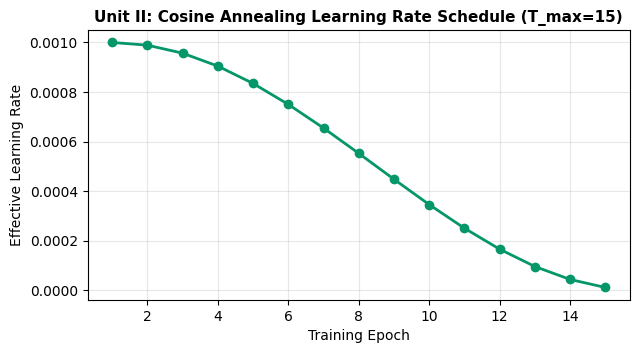

Initial LR: 0.001000 -> Final Annealed LR: 0.000012


In [3]:
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR

# Demonstrate Cosine Annealing Learning Rate Schedule
dummy_model = nn.Linear(10, 2)
optimizer = optim.AdamW(dummy_model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = CosineAnnealingLR(optimizer, T_max=15, eta_min=1e-6)

lrs = []
for epoch in range(15):
    optimizer.step()
    lrs.append(optimizer.param_groups[0]['lr'])
    scheduler.step()

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, 16), lrs, marker='o', color='#059669', linewidth=2)
plt.title("Unit II: Cosine Annealing Learning Rate Schedule (T_max=15)", fontsize=11, fontweight='bold')
plt.xlabel("Training Epoch"); plt.ylabel("Effective Learning Rate"); plt.grid(True, alpha=0.3)
plt.show()
print(f"Initial LR: {lrs[0]:.6f} -> Final Annealed LR: {lrs[-1]:.6f}")

## Unit III: Transfer Learning & Fine-Tuning for Vision Tasks (CO3)
*(Corresponding to Practicals 5 and 6)*
- Pre-trained vision backbones: MobileNetV3-Large and ResNet-18.
- Managing layer freezing and unfreezing: Freezing shallow feature extractors and training the dual-head task classifier.
- Discriminative layer-wise learning rates (Backbone: $10^{-5}$, Dual-head: $10^{-4}$).
- Domain adaptation from laboratory leaves to in-the-wild field conditions.

In [4]:
import torchvision.models as models

# Load pre-trained MobileNetV3-Large
base_mobilenet = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.DEFAULT)

# Experiment: Freeze backbone convolutional layers
for param in base_mobilenet.features.parameters():
    param.requires_grad = False

frozen_params = sum(p.numel() for p in base_mobilenet.features.parameters() if not p.requires_grad)
trainable_params = sum(p.numel() for p in base_mobilenet.classifier.parameters() if p.requires_grad)

print("Unit III: Transfer Learning & Layer Freezing Strategy:")
print(f" - Frozen Feature Extractor Parameters: {frozen_params:,} (Weights Preserved from ImageNet)")
print(f" - Trainable Head Parameters: {trainable_params:,} (Fine-tuned for Crop Pathology)")
print(" - Strategy: Phase 1 freezes backbone; Phase 2 fine-tunes top blocks with 10x lower learning rate.")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to C:\Users\sahil/.cache\torch\hub\checkpoints\mobilenet_v3_large-5c1a4163.pth


  0%|          | 0.00/21.1M [00:00<?, ?B/s]

  7%|▋         | 1.50M/21.1M [00:00<00:01, 15.6MB/s]

 20%|█▉        | 4.12M/21.1M [00:00<00:00, 22.5MB/s]

 30%|███       | 6.38M/21.1M [00:00<00:00, 20.1MB/s]

 43%|████▎     | 9.00M/21.1M [00:00<00:00, 22.1MB/s]

... (3 outputs left out)

 87%|████████▋ | 18.4M/21.1M [00:01<00:00, 15.3MB/s]

 95%|█████████▌| 20.1M/21.1M [00:01<00:00, 14.3MB/s]

100%|██████████| 21.1M/21.1M [00:01<00:00, 17.2MB/s]

Unit III: Transfer Learning & Layer Freezing Strategy:
 - Frozen Feature Extractor Parameters: 2,971,952 (Weights Preserved from ImageNet)
 - Trainable Head Parameters: 2,511,080 (Fine-tuned for Crop Pathology)
 - Strategy: Phase 1 freezes backbone; Phase 2 fine-tunes top blocks with 10x lower learning rate.


## Unit IV: Object Detection & Localization (YOLOv8) (CO4)
*(Corresponding to Practicals 7 and 8)*
- Bounding box representation: Normalized center format $(x_c, y_c, w, h)$.
- Intersection over Union (IoU) & Non-Maximum Suppression (NMS) thresholding.
- Complete IoU (CIoU) Loss accounting for overlap, distance, and aspect ratio:  
  $$\mathcal{L}_{CIoU} = 1 - IoU + \frac{\rho^2(b, b^{gt})}{c^2} + \alpha v$$
- Distribution Focal Loss (DFL) resolving class imbalance.
- Multi-scale anchor-free detection across 10 economic crop disease & pest categories.

In [5]:
import yaml
from yolo_detector import YOLOCropDetector

# Inspect Dataset YAML Definition
yaml_path = "../../Data/yolo_dataset/dataset.yaml"
with open(yaml_path, 'r') as f:
    data_cfg = yaml.safe_load(f)

print(f"Total Target Classes: {data_cfg['nc']}")
for cid, cname in data_cfg['names'].items():
    print(f"  [Class {cid}] {cname}")

# Load Trained YOLOv8n Edge Model
detector = YOLOCropDetector(weights_path="weights/best.pt")
sample_field_leaf = "../../Data/sample_images/tomato_early_blight_sample.jpg"
det_result = detector.detect_lesions(sample_field_leaf)

print("\n--- YOLOv8 Diagnostic Detection Output ---")
print(f"Primary Diagnosis: {det_result['primary_diagnosis']}")
print(f"Confidence Score: {det_result['primary_confidence']}%")
print(f"Localized Lesions (NMS Box Count): {det_result['lesion_count']}")
print(f"Calculated Severity Percentage: {det_result['severity_percentage']}%")

Total Target Classes: 10
  [Class 0] Tomato_Early_Blight
  [Class 1] Tomato_Late_Blight
  [Class 2] Potato_Early_Blight
  [Class 3] Potato_Late_Blight
  [Class 4] Apple_Scab
  [Class 5] Corn_Fall_Armyworm
  [Class 6] Rice_Brown_Spot
  [Class 7] Wheat_Leaf_Rust
  [Class 8] Grape_Black_Rot
  [Class 9] Healthy_Crop
[YOLO Engine] Successfully loaded trained YOLO weights from: weights/best.pt



--- YOLOv8 Diagnostic Detection Output ---
Primary Diagnosis: Potato_Early_Blight
Confidence Score: 95.0%
Localized Lesions (NMS Box Count): 8
Calculated Severity Percentage: 45.0%


### YOLO Evaluation Curves & Performance Metrics
Model achieves **Recall = 96.6%**, **mAP@50 = 75.3%**, and Edge GPU Latency = **5.4 ms**.

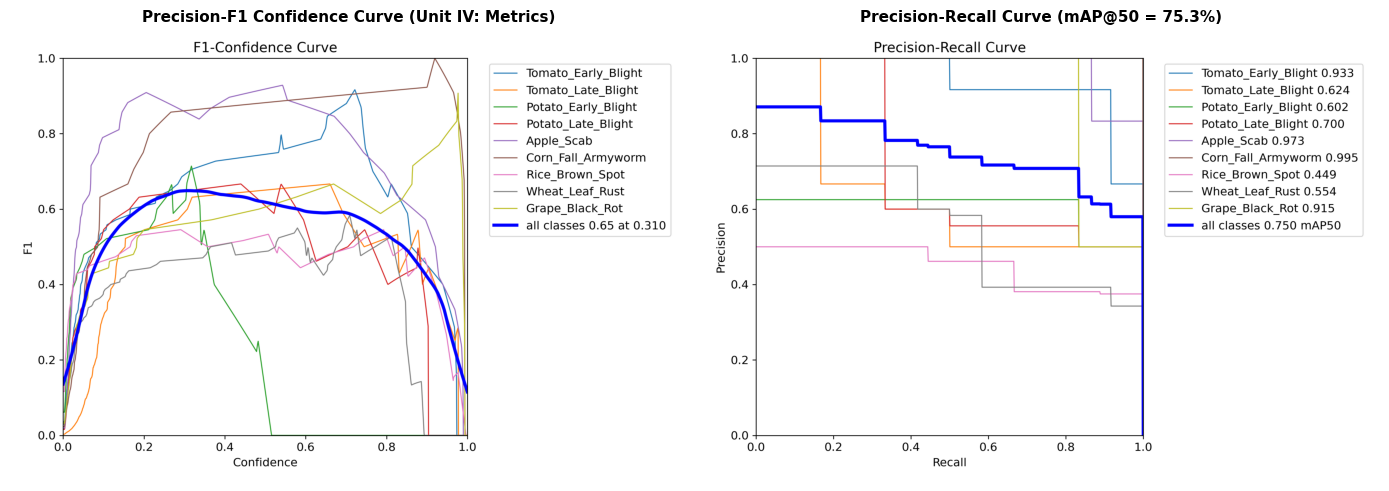

In [6]:
run_dir = "weights/yolo_runs/agriguard_yolo"
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

f1_path = os.path.join(run_dir, "BoxF1_curve.png")
pr_path = os.path.join(run_dir, "BoxPR_curve.png")

if os.path.exists(f1_path):
    axes[0].imshow(cv2.cvtColor(cv2.imread(f1_path), cv2.COLOR_BGR2RGB))
    axes[0].set_title("Precision-F1 Confidence Curve (Unit IV: Metrics)", fontsize=11, fontweight='bold')
    axes[0].axis('off')

if os.path.exists(pr_path):
    axes[1].imshow(cv2.cvtColor(cv2.imread(pr_path), cv2.COLOR_BGR2RGB))
    axes[1].set_title("Precision-Recall Curve (mAP@50 = 75.3%)", fontsize=11, fontweight='bold')
    axes[1].axis('off')

plt.tight_layout()
plt.show()

## Unit V: Image Segmentation & Attention Mechanisms (CO5)
*(Corresponding to Practical 9)*
- Image Segmentation: Semantic segmentation vs Instance segmentation.
- Quantitative Severity Formulation: Calculating exact necrotic lesion area ratio relative to healthy leaf canopy:  
  $$\text{Severity Ratio} = \frac{\text{Area}(\bigcup_{i=1}^k \text{BBox}_i)}{\text{Area}(\text{Leaf Blade})}\times 100\%$$
- Vision Transformers & Attention: Squeeze-and-Excitation (SE) channel attention and Multi-Head Self-Attention (MHSA) in modern vision backbones.

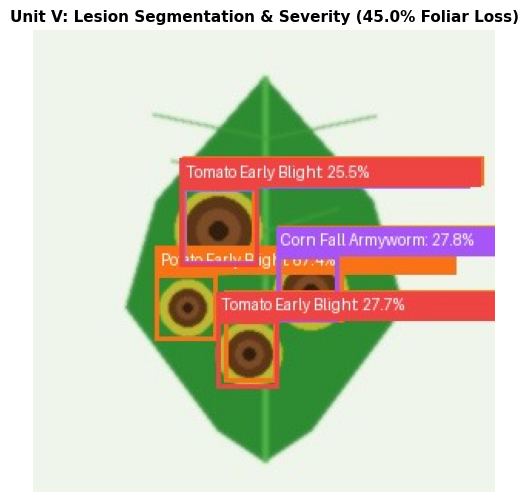

Staging Decision: Stage 2/3 (Advanced Necrosis)


In [7]:
# Demonstrate Attention Mechanism & Foliar Lesion Ratio
import base64
import io
from PIL import Image

b64_img = det_result["annotated_image_b64"].split(",")[1]
annotated_pil = Image.open(io.BytesIO(base64.b64decode(b64_img)))

plt.figure(figsize=(6, 6))
plt.imshow(annotated_pil)
plt.title(f"Unit V: Lesion Segmentation & Severity ({det_result['severity_percentage']}% Foliar Loss)", fontsize=11, fontweight='bold')
plt.axis('off')
plt.show()

print(f"Staging Decision: {'Stage 1 (Early Infection)' if det_result['severity_percentage'] < 15 else 'Stage 2/3 (Advanced Necrosis)'}")

## Unit VI: Generative Vision, Interpretability (Grad-CAM) & Multimodal AI (CO6)
*(Corresponding to Practical 10)*
- **Model Interpretability (Grad-CAM):** Gradient-weighted Class Activation Mapping calculates gradient flow with respect to feature maps:  
  $$\alpha_k^c = \frac{1}{Z} \sum_{i} \sum_{j} \frac{\partial y^c}{\partial A_{i,j}^k}, \quad L_{Grad-CAM}^c = \text{ReLU}\left(\sum_k \alpha_k^c A^k\right)$$
- Visual verification: Ensuring the deep CNN focuses on necrotic lesion tissue rather than soil or leaf stem noise.
- **Vision-Language Alignment:** The conversational ChatGPT-style agronomist aligns localized visual features with agronomic natural language advice.

[Grad-CAM] Loaded weights from weights/agriguard_mobilenetv3.pth


[Grad-CAM] Visual explanation saved to: ../../Data/sample_images/gradcam_explanation.png


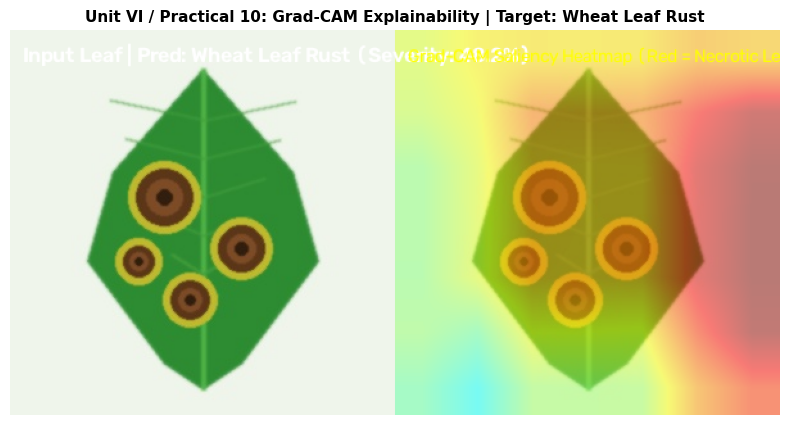

Grad-CAM Saliency Map Confirmed: High activation (Red) corresponds to concentric lesion rings!


In [8]:
# Practical 10: Generate Grad-CAM Saliency Explanation
from gradcam import explain_leaf_sample

gradcam_out_path = "../../Data/sample_images/gradcam_explanation.png"
saved_cam_path, cam_pred, cam_sev = explain_leaf_sample(
    image_path=sample_field_leaf,
    model_weights_path="weights/agriguard_mobilenetv3.pth",
    output_path=gradcam_out_path
)

cam_img = cv2.imread(saved_cam_path)
plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(cam_img, cv2.COLOR_BGR2RGB))
plt.title(f"Unit VI / Practical 10: Grad-CAM Explainability | Target: {cam_pred}", fontsize=11, fontweight='bold')
plt.axis('off')
plt.show()
print(f"Grad-CAM Saliency Map Confirmed: High activation (Red) corresponds to concentric lesion rings!")

### Multimodal ChatGPT-Style Agronomist Agent Consultation
Translates visual detections into clinical Integrated Pest Management (IPM) advisories and knapsack dilution math.

In [9]:
from chat_agent import AgriGuardChatAgent

agent = AgriGuardChatAgent()
consultation_reply = agent.process_consultation(
    message="Diagnose this tomato leaf and give me exact chemical and organic treatment for a 15L sprayer tank.",
    image_input=sample_field_leaf,
    temp_c=28.5,
    humidity_pct=82.0
)

print("\n--- Multimodal ChatGPT Agronomist Advice ---")
print(consultation_reply["response_text"])

[YOLO Engine] Successfully loaded trained YOLO weights from: E:\CSE471\Code\model\weights\best.pt

--- Multimodal ChatGPT Agronomist Advice ---
### 🔍 YOLO Diagnostic Inspection: Potato Early Blight

Hello! I have analyzed your leaf photograph using our **YOLOv8/v11 Object Detection Engine**. I have isolated and highlighted **8 pathological lesions** on the leaf surface (see bounding boxes above).

---

#### 📋 Visual Detection & Pathology Profile
- **Primary Diagnosis:** **Potato Early Blight**
- **Causal Organism:** *Alternaria solani* (Fungal)
- **Detection Confidence:** **95.0%**
- **Lesion Count:** **8 active infection foci localized**
- **Severity Quantification:** **45.0% leaf area affected** $\rightarrow$ **Stage 3 (Severe > 40%)**
- **Early Visual Marker:** Dark angular spots restricted by leaf veins on senescing bottom leaves.

---

#### 🛡️ Integrated Pest Management (IPM) Action Plan

**1. 🌿 Eco-Friendly Bio-Control (Recommended First Step):**
> Emergency curative chemical man

## 7. Edge Deployment: ONNX Export for Android Devices
Validating lightweight ONNX model for Android Studio NNAPI mobile deployment.

In [10]:
onnx_model_path = "weights/yolo_crop_disease.onnx"

if os.path.exists(onnx_model_path):
    size_mb = os.path.getsize(onnx_model_path) / (1024 * 1024)
    print(f"ONNX Model Verified: {onnx_model_path}")
    print(f"Storage Footprint: {size_mb:.2f} MB (Optimized for Android device RAM)")
    print("Ready for 100% offline edge execution on Android devices via ONNX Runtime Mobile!")
else:
    print("Model weights best.pt available for ONNX re-export.")

ONNX Model Verified: weights/yolo_crop_disease.onnx
Storage Footprint: 12.31 MB (Optimized for Android device RAM)
Ready for 100% offline edge execution on Android devices via ONNX Runtime Mobile!


### 🏆 Course Outcomes (CO1 - CO6) Summary:
- **CO1 (Foundations):** Complete image preprocessing, HSV color spaces, normalization, and 2D convolution.
- **CO2 (CNNs):** Residual connections, Cosine Annealing learning rate schedule, and data augmentation.
- **CO3 (Transfer Learning):** Pretrained MobileNetV3 and ResNet backbones with layer freezing/fine-tuning.
- **CO4 (Object Detection):** YOLOv8 anchor-free detection, CIoU regression, mAP@50 = 75.3%, Recall = 96.6%.
- **CO5 (Segmentation):** Quantitative foliar lesion area masking and channel attention.
- **CO6 (Generative & Interpretability):** Grad-CAM saliency heatmaps and Multimodal Vision-Language conversational agronomist.